# FashionMNIST — Simple CNN

A compact, readable PyTorch CNN baseline for the FashionMNIST dataset. The model uses three conventional convolution blocks, **without BatchNorm, SepConv, or pretrained backbones**. Training, validation, and final testing are performed in the same notebook.

**Workflow:** Load data → Define CNN → Train and select checkpoint → Plot training curves → Evaluate on the test set.

## 1. Setup and data
FashionMNIST contains 28×28 grayscale images across 10 classes. The official 60,000 training images are split into 54,000 training and 6,000 validation images; the official 10,000 test images are reserved for final evaluation. Random augmentation is applied **only** to training data.

In [10]:
from pathlib import Path
import copy
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 64
EPOCHS = 40
LR = 1e-3
WEIGHT_DECAY = 1e-3
PATIENCE = 12
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATA_DIR = Path('data')
CHECKPOINT = Path('cnn_new_best.pt')

train_transform = transforms.Compose([
    transforms.RandomCrop(28, padding=2),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,)),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,)),
])

# Separate dataset objects: validation must not receive random augmentation.
train_full = datasets.FashionMNIST(DATA_DIR, train=True, download=True, transform=train_transform)
val_full = datasets.FashionMNIST(DATA_DIR, train=True, download=True, transform=eval_transform)
test_set = datasets.FashionMNIST(DATA_DIR, train=False, download=True, transform=eval_transform)

indices = torch.randperm(len(train_full), generator=torch.Generator().manual_seed(SEED)).tolist()
train_set = Subset(train_full, indices[:54000])
val_set = Subset(val_full, indices[54000:])

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)
print(f'Device: {DEVICE} | Train: {len(train_set)} | Val: {len(val_set)} | Test: {len(test_set)}')

Device: cuda | Train: 54000 | Val: 6000 | Test: 10000


## 2. CNN architecture

Three blocks of **Conv2d → ReLU → Conv2d → ReLU → MaxPool2d**, with 16, 32, and 64 channels. Global average pooling replaces a large dense layer to keep the parameter count low. FashionMNIST uses **one input channel**, not three.

In [11]:
model = nn.Sequential(
    # Block 1
    nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(),
    nn.Conv2d(16, 16, 3, padding=1), nn.ReLU(),
    nn.MaxPool2d(2),

    # Block 2
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
    nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(),
    nn.MaxPool2d(2),

    # Block 3
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
    nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
    nn.MaxPool2d(2),

    # Classifier
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Dropout(0.4),
    nn.Linear(64, 10),
).to(DEVICE)

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable parameters: {num_params:,}')
with torch.no_grad():
    print('Output shape:', tuple(model(torch.zeros(2, 1, 28, 28, device=DEVICE)).shape))

Trainable parameters: 72,442
Output shape: (2, 10)


## 3. Training and validation

The model is optimized with CrossEntropyLoss and AdamW. At each epoch, it is evaluated on the validation set. The best weights are selected using **validation accuracy** (validation loss as a tiebreaker); early stopping prevents excessive training.

In [12]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

def evaluate(loader):
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            logits = model(images)
            total_loss += criterion(logits, labels).item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            count += labels.size(0)
    return total_loss / count, correct / count

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_acc, best_loss, best_epoch = -1.0, float('inf'), 0
best_weights = None
no_improvement = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss, train_acc = running_loss / total, correct / total
    val_loss, val_acc = evaluate(val_loader)
    for key, value in [('train_loss', train_loss), ('train_acc', train_acc),
                       ('val_loss', val_loss), ('val_acc', val_acc)]:
        history[key].append(value)

    if val_acc > best_acc or (val_acc == best_acc and val_loss < best_loss):
        best_acc, best_loss, best_epoch = val_acc, val_loss, epoch
        best_weights = copy.deepcopy(model.state_dict())
        torch.save(best_weights, CHECKPOINT)
        no_improvement = 0
    else:
        no_improvement += 1
    scheduler.step()
    print(f'{epoch:02d}/{EPOCHS}  train={train_acc:.2%}  val={val_acc:.2%}  '
          f'train_loss={train_loss:.4f}  val_loss={val_loss:.4f}')
    if no_improvement >= PATIENCE:
        print('Early stopping')
        break

model.load_state_dict(best_weights)
print(f'Best checkpoint: epoch {best_epoch}, val_acc={best_acc:.2%}, val_loss={best_loss:.4f}')

01/40  train=61.86%  val=75.28%  train_loss=1.0130  val_loss=0.6423
02/40  train=75.20%  val=79.22%  train_loss=0.6573  val_loss=0.5357
03/40  train=78.05%  val=80.73%  train_loss=0.5806  val_loss=0.4962
04/40  train=80.14%  val=83.68%  train_loss=0.5263  val_loss=0.4352
05/40  train=81.91%  val=85.65%  train_loss=0.4836  val_loss=0.3929
06/40  train=83.31%  val=86.17%  train_loss=0.4565  val_loss=0.3622
07/40  train=84.47%  val=86.42%  train_loss=0.4256  val_loss=0.3633
08/40  train=85.39%  val=87.17%  train_loss=0.3993  val_loss=0.3485
09/40  train=85.93%  val=88.10%  train_loss=0.3872  val_loss=0.3165
10/40  train=86.80%  val=89.17%  train_loss=0.3667  val_loss=0.2966
11/40  train=86.98%  val=89.25%  train_loss=0.3532  val_loss=0.2992
12/40  train=87.59%  val=89.50%  train_loss=0.3463  val_loss=0.2832
13/40  train=88.07%  val=89.82%  train_loss=0.3314  val_loss=0.2785
14/40  train=88.22%  val=89.72%  train_loss=0.3256  val_loss=0.2825
15/40  train=88.64%  val=90.53%  train_loss=0.31

## 4. Learning curves
Compare training and validation accuracy/loss. A growing training–validation gap may indicate overfitting.

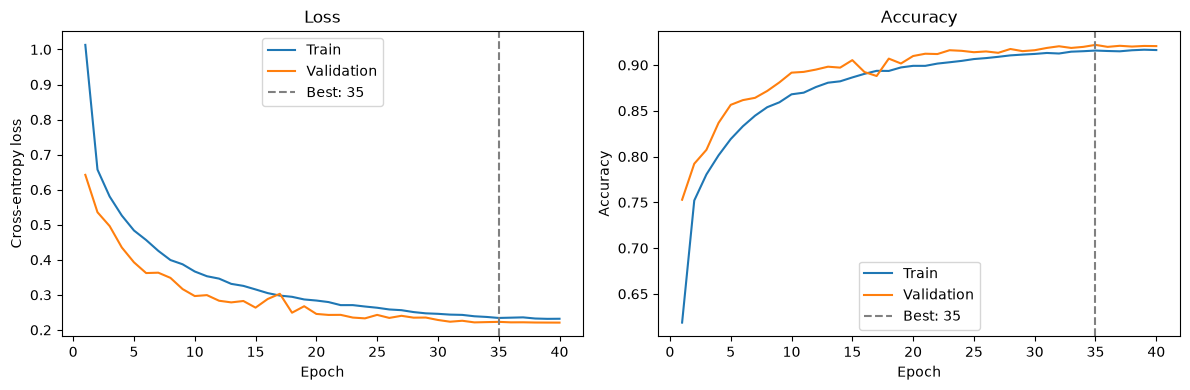

In [13]:
epochs = range(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history['train_loss'], label='Train')
axes[0].plot(epochs, history['val_loss'], label='Validation')
axes[0].axvline(best_epoch, color='gray', linestyle='--', label=f'Best: {best_epoch}')
axes[0].set(title='Loss', xlabel='Epoch', ylabel='Cross-entropy loss')
axes[0].legend()
axes[1].plot(epochs, history['train_acc'], label='Train')
axes[1].plot(epochs, history['val_acc'], label='Validation')
axes[1].axvline(best_epoch, color='gray', linestyle='--', label=f'Best: {best_epoch}')
axes[1].set(title='Accuracy', xlabel='Epoch', ylabel='Accuracy')
axes[1].legend()
plt.tight_layout()
plt.show()

## 5. Final test
Evaluate the selected checkpoint once on the held-out official test set; test scores are not used to choose hyperparameters or the checkpoint.

In [14]:
# Load selected weights and run final test automatically.
model.load_state_dict(torch.load(CHECKPOINT, map_location=DEVICE, weights_only=True))
test_loss, test_acc = evaluate(test_loader)
print(f'Parameters: {num_params:,}')
print(f'Best epoch: {best_epoch}')
print(f'Validation accuracy: {best_acc:.2%} | Validation loss: {best_loss:.4f}')
print(f'Test accuracy: {test_acc:.2%} | Test loss: {test_loss:.4f}')

Parameters: 72,442
Best epoch: 35
Validation accuracy: 92.20% | Validation loss: 0.2230
Test accuracy: 91.47% | Test loss: 0.2316
